# Amazon Product Data: Bivariate Analysis

## Prep: importing libraries and datset

In [1]:
#code

%pip install kagglehub
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Note: you may need to restart the kernel to use updated packages.
Path to dataset files: /Users/isishassan/.cache/kagglehub/datasets/asaniczka/uk-optimal-product-price-prediction/versions/3


import libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt # viz
import seaborn as sns # better viz
import numpy as np # numerical python
import os 

In [8]:
df = pd.read_csv(r"/Users/isishassan/.cache/kagglehub/datasets/asaniczka/uk-optimal-product-price-prediction/versions/3/amz_uk_price_prediction_dataset.csv")

In [9]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


## Part 1

#### Instructions

**Objective:** Understand the relationship between product categories and their best-seller status.

**Crosstab Analysis:**

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

In [62]:
df["category"].unique()

array(['Hi-Fi Speakers', 'CD, Disc & Tape Players', 'Wearable Technology',
       'Light Bulbs', 'Bathroom Lighting',
       'Heating, Cooling & Air Quality', 'Coffee & Espresso Machines',
       'Lab & Scientific Products', 'Smart Speakers',
       'Motorbike Clothing', 'Motorbike Accessories',
       'Motorbike Batteries', 'Motorbike Boots & Luggage',
       'Motorbike Chassis', 'Handmade Home & Kitchen Products',
       'Hardware', 'Storage & Home Organisation',
       'Fireplaces, Stoves & Accessories', 'PC Gaming Accessories',
       'USB Gadgets', 'Blank Media Cases & Wallets', 'Car & Motorbike',
       'Boys', 'Sports & Outdoors', 'Microphones', 'String Instruments',
       'Karaoke Equipment', 'PA & Stage',
       'General Music-Making Accessories', 'Wind Instruments',
       'Handmade Gifts', 'Fragrances', 'Calendars & Personal Organisers',
       'Furniture & Lighting', 'Computer Printers', 'Ski Goggles',
       'Snowboards', 'Skiing Poles', 'Downhill Ski Boots',
       'Hiki

In [63]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])                   #crosstab of category and bestsellr

row_percentages = crosstab_result.div(crosstab_result.sum(axis=1), axis=0) * 100    #divide values by the sum of the values in axis 0 (i.e. horizontal)
row_percentages

row_percentages.sort_values(by=True, ascending=False)                               #sorting my values by highest % of true

#row_percentages_flat.columns = row_percentages.columns.get_level_values(1)     #flattening my columns, so i can sort
#row_percentages.sort_values(by=('isBestSeller', "True"), ascending=False)

isBestSeller,False,True
category,,
Grocery,94.186533,5.813467
Smart Home Security & Lighting,94.230769,5.769231
Health & Personal Care,94.231372,5.768628
Mobile Phone Accessories,95.752896,4.247104
Power & Hand Tools,96.466105,3.533895
...,...,...
"CD, Disc & Tape Players",100.000000,0.000000
General Music-Making Accessories,100.000000,0.000000
Snowboard Boots,100.000000,0.000000


Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.

In [43]:
#chi square: instal what i need
%pip install scipy

from scipy.stats import chi2_contingency

Note: you may need to restart the kernel to use updated packages.


In [56]:
chi2_pvalue = chi2_contingency(crosstab_result)           #run test

from scipy.stats import chi2_contingency

_, p_value, _, _ = chi2_contingency(crosstab_result)

p_value < 0.05                                              #check if below 0.05

np.True_

In [57]:
#cramers V

from scipy.stats.contingency import association

In [58]:
association(crosstab_result, method='cramer')

0.1222829439760564

There is a weak association between category and best seller distribution

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [97]:
#reduce no. of categories to only include those that have at least 1 bestseller

df_subset_1 = crosstab_result[crosstab_result[True] > 0]

#df_subset_1                 
 
#not enough reduction, expanding my exlcusions to also exlude small categories and the largest category, so that my graph looks manageable

df_subset = crosstab_result[(crosstab_result[True] >= 10) & (crosstab_result.sum(axis=1) >= 9000) & (crosstab_result.sum(axis=1) < 20000)]

df_subset

isBestSeller,False,True
category,,
Arts & Crafts,9319,230
Baby,14709,341
Baby & Toddler Toys,9332,24
Bath & Body,19059,33
Beauty,19010,302
...,...,...
Sports Supplements,9425,18
Sports Toys & Outdoor,9261,58
Storage & Organisation,9414,155


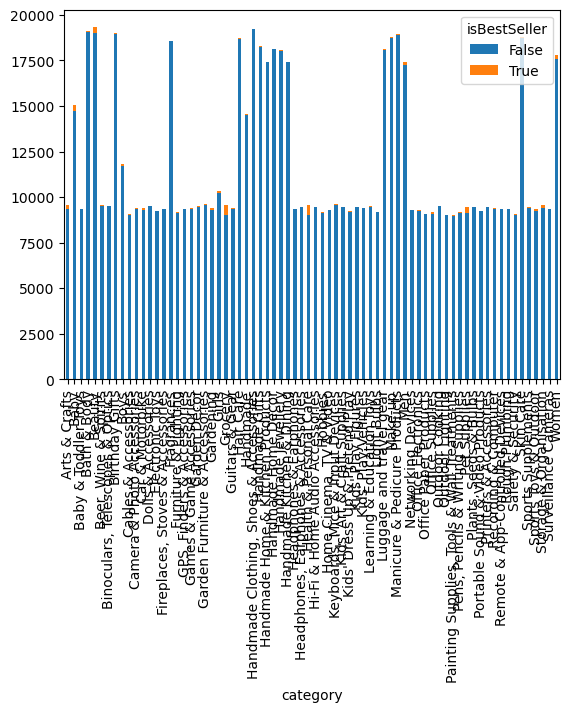

In [98]:
#stacked bar chart

df_subset.plot(kind='bar', stacked=True)
plt.show()

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands

#### Instructions

Objective: Investigate how different product categories influence product prices.

Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

In [ ]:
"""
1. find IQR (see yesterday)
2. determine bounds
3. use & conditions to create df without outliers
"""
#1
q1 = np.percentile(df['price'], 25)
q3 = np.percentile(df['price'], 75)

iqr = q3-q1

#2
upper_bound = q3 + iqr * 1.5
lower_bound = q1 - iqr * 1.5


df_prices = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)]

df_prices




,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
10,11,B08VDNCZT9,JBL Charge 5 - Portable Bluetooth Speaker with...,4.8,11920,139.00,False,0,Hi-Fi Speakers
19,20,B07NQCKJSH,Echo Studio | Our best-sounding Wi-Fi and Blue...,4.5,14222,164.99,False,0,Hi-Fi Speakers
25,26,B0BLS36M5R,All-new Echo Show 8 | 3rd generation (2023 rel...,0.0,0,149.99,False,0,Hi-Fi Speakers
28,29,B096G3R7C3,JBL PartyBox110 Portable Indoor and Outdoor Pa...,4.8,153,289.00,False,0,Hi-Fi Speakers
31,32,B08MQRDDYB,"Echo Show 15 | Full HD 15.6"" smart display wit...",4.4,2616,199.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443619,2828560,B07JLZB7YY,Motorcycle Clothing Suit - Motorbike Suit With...,0.0,0,166.99,False,0,Motorbike Clothing
2443627,2828568,B005QN452A,Racer Beasty Ladies Leather Motorbike Trousers,3.8,181,152.58,False,0,Motorbike Clothing
2443638,2828579,B084R261ML,"SHIMA EXO Vented, Motorbike Shoes for Women | ...",4.6,209,108.77,False,0,Motorbike Clothing
2443641,2828582,B07JM93SCC,Motorcycle Clothing Suit - Motorbike Suit With...,0.0,0,166.99,False,0,Motorbike Clothing


**Violin Plots**

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.

In [ ]:
#top 20 categories by value count

frequency_table_category = df.category.value_counts()                                 #getting my value counts per category

top_20 = frequency_table_category.sort_values(ascending=False).head(20)                #getting my top 20

df_top_20 = df[df['category'].isin(top_20.index)]                                      

/var/folders/vl/4lkjvsxx3pv_m7ynmbqrfd780000gn/T/ipykernel_3138/2486641232.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top_20, x="category", y="price", palette="coolwarm")


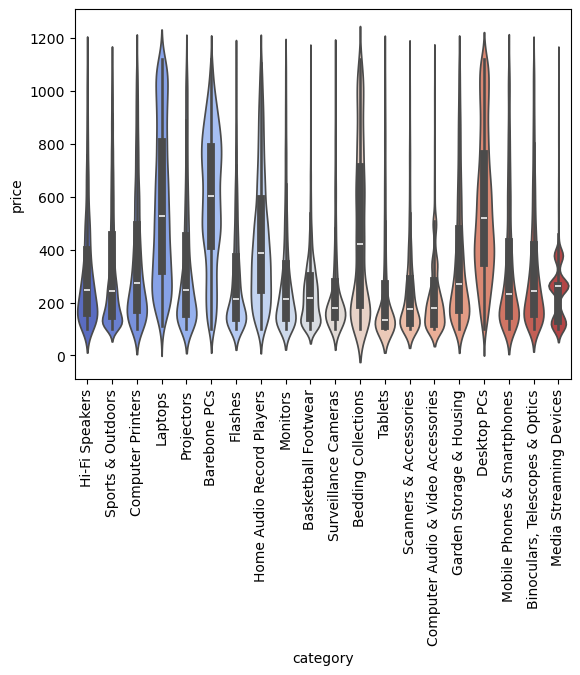

In [140]:
#violin plot, top 20 categories by value count

sns.violinplot(data=df_top_20, x="category", y="price", palette="coolwarm")
plt.xticks(rotation=90)                         #rotating my x-labels
plt.show()

Insight: In the top 20 categories by volume, there is huge price variation in "Sports & Outdoor", "Barebone PCs" and "Desktop PCs". Very noteworthy is "Media Streaming Devices", where prices are concentrated in three "low", "middle", and "high" pricepoints.

In [153]:
#top 20, median - using df_prices again, i.e. data without outliers.

df_prices

#getting the categories with the highest median price, by grouping median price per category and soritng my values
top_20_median_cats = df_prices[["category", "price"]].groupby("category").median().sort_values("price",ascending=False).head(20)

#using the same function as above, although i don't fully understand it
df_median_price = df_prices[df_prices['category'].isin(top_20_median_cats.index)]  




/var/folders/vl/4lkjvsxx3pv_m7ynmbqrfd780000gn/T/ipykernel_3138/637121200.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_median_price, x="category", y="price", palette="Reds")


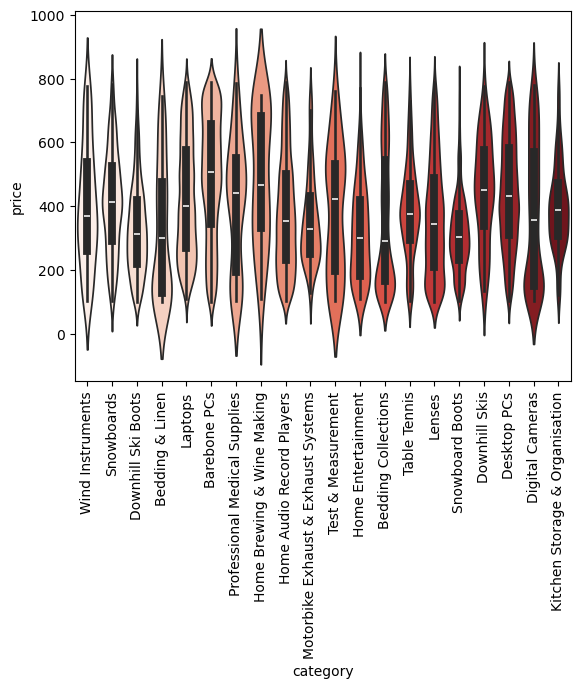

In [160]:
#turning it into a violin plot

sns.violinplot(data=df_median_price, x="category", y="price", palette="Reds")
plt.xticks(rotation=90)                         #rotating my x-labels, so i can read them
plt.show()

Bar Chart: Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.

In [167]:
frequency_table_category = df.category.value_counts()                                 #getting my value counts per category

top_10 = frequency_table_category.sort_values(ascending=False).head(10)                #getting my top 10

df_top_10 = df[df['category'].isin(top_10.index)]   

/var/folders/vl/4lkjvsxx3pv_m7ynmbqrfd780000gn/T/ipykernel_3138/1068371417.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top_10, x="category", y="price", palette="Blues", errorbar=None, estimator = "mean")


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Laptops'),
  Text(2, 0, 'Projectors'),
  Text(3, 0, 'Barebone PCs'),
  Text(4, 0, 'Home Audio Record Players'),
  Text(5, 0, 'Monitors'),
  Text(6, 0, 'Garden Storage & Housing'),
  Text(7, 0, 'Desktop PCs'),
  Text(8, 0, 'Mobile Phones & Smartphones'),
  Text(9, 0, 'Binoculars, Telescopes & Optics')])

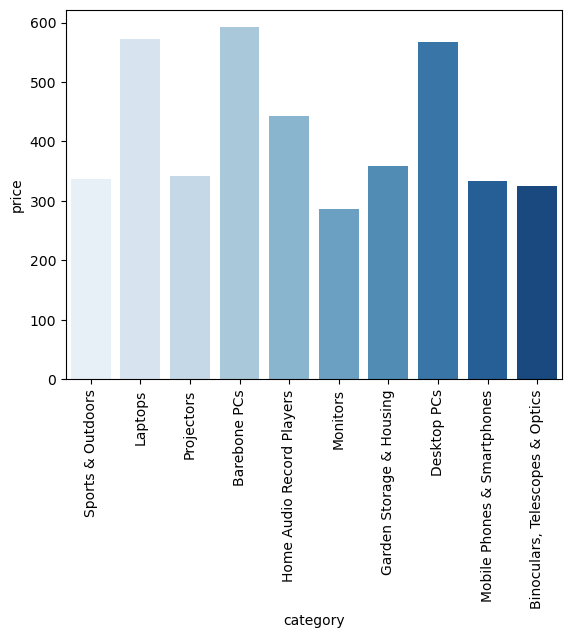

In [ ]:
#bar chart, avg price

sns.barplot(data=df_top_10, x="category", y="price", palette="Blues", errorbar=None, estimator = "mean")
plt.xticks(rotation=90)                         #QQ how do i get this to not show?

Insight:  Barebone PCs, Desktop PCs and Laptops have the highest average price

In [173]:
#highest avg price

#getting the categories with the highest avg price, by grouping median price per category and soritng my values
top_10_mean_cats = df_prices[["category", "price"]].groupby("category").mean().sort_values("price",ascending=False).head(10)

#using the same function as above, although i don't fully understand it
df_mean_price = df_prices[df_prices['category'].isin(top_10_mean_cats.index)]  

/var/folders/vl/4lkjvsxx3pv_m7ynmbqrfd780000gn/T/ipykernel_3138/330163914.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_mean_price, x="category", y="price", palette="Blues", errorbar=None, estimator = "mean")


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Wind Instruments'),
  Text(1, 0, 'Snowboards'),
  Text(2, 0, 'Laptops'),
  Text(3, 0, 'Barebone PCs'),
  Text(4, 0, 'Professional Medical Supplies'),
  Text(5, 0, 'Home Brewing & Wine Making'),
  Text(6, 0, 'Table Tennis'),
  Text(7, 0, 'Downhill Skis'),
  Text(8, 0, 'Desktop PCs'),
  Text(9, 0, 'Kitchen Storage & Organisation')])

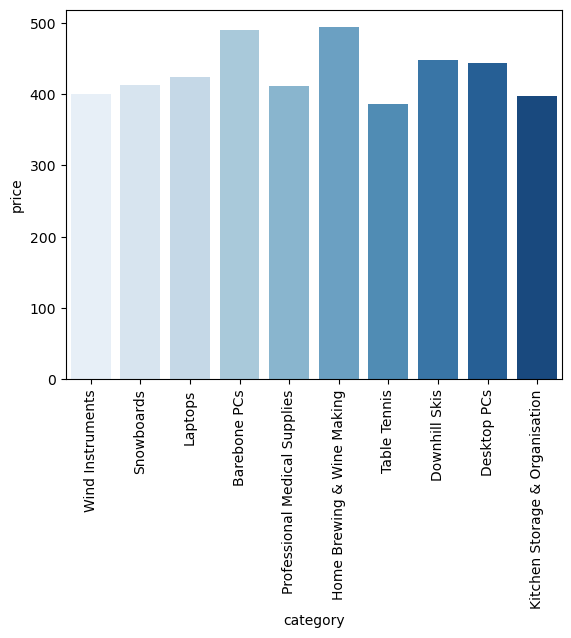

In [176]:
#bar chart
#bar chart, avg price

sns.barplot(data=df_mean_price, x="category", y="price", palette="Blues", errorbar=None, estimator = "mean")
plt.xticks(rotation=90)                         

#QQ how do i get the xticks to onl show on the image when i am rotating them?
#QQ how can i sort my results by mean?

Box Plots:
Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [179]:
#i already have the top 10 categories from before
df_top_10
#but i want to exclude the products without ratings

df_top_10_rated = df_top_10[df_top_10["stars"] > 0]

/var/folders/vl/4lkjvsxx3pv_m7ynmbqrfd780000gn/T/ipykernel_3138/1145069264.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_10_rated, x="category", y="stars", palette="coolwarm", legend=True)


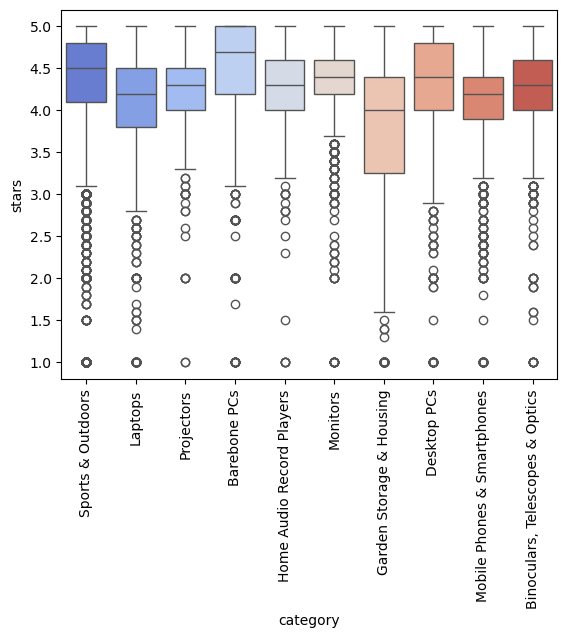

In [183]:
sns.boxplot(data=df_top_10_rated, x="category", y="stars", palette="coolwarm", legend=True)
plt.xticks(rotation=90)
plt.show()

Insight: Barebone PCs get the highest median rating out of the 10 biggest categories

In [ ]:
#best median rating overall

#1 getting only rated products
df_rated = df[df["stars"] > 0]

#2 grouping by median, getting top 10 categories
top_10_median_rating = df_rated[["category", "stars"]].groupby("category").median().sort_values("stars",ascending=False).head(10)

#3 filtering my df by these categories
df_median_rating = df_rated[df_rated["category"].isin(top_10_median_rating.index)]  

/var/folders/vl/4lkjvsxx3pv_m7ynmbqrfd780000gn/T/ipykernel_3138/3170840237.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_median_rating, x="category", y="stars", palette="coolwarm", legend=True)


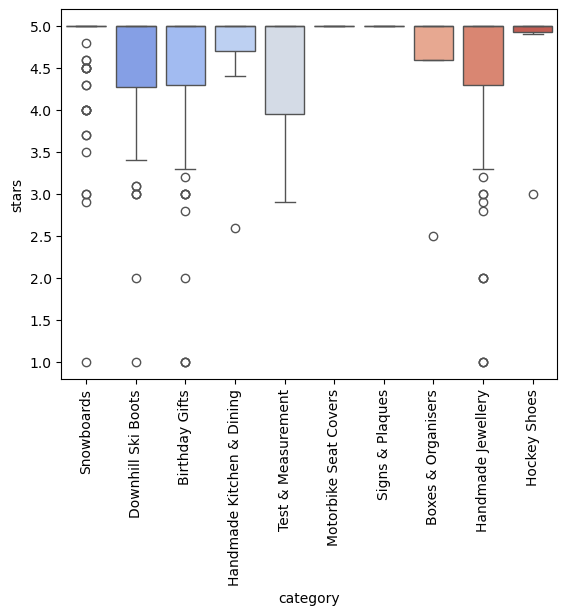

In [186]:
sns.boxplot(data=df_median_rating, x="category", y="stars", palette="coolwarm", legend=True)
plt.xticks(rotation=90)
plt.show()

## Part 3 Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

### Instructions

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?

In [194]:
#i need to look at the correct dataset. df_prices excludes outliers, but it still contains unrated products

df_price_rating = df_prices[df_prices["stars"] > 0]

In [195]:
#pearson
round(float(df_price_rating["price"].corr(df_price_rating["stars"], method="pearson")), 2)


-0.0

There is no correlation

In [ ]:
#spearman
df_price_rating["price"].corr(df_price_rating["stars"], method="spearman")

np.float64(-0.0019614554156985628)

There is very, very, very mininal negative correlation

**Visualizations:**

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.**

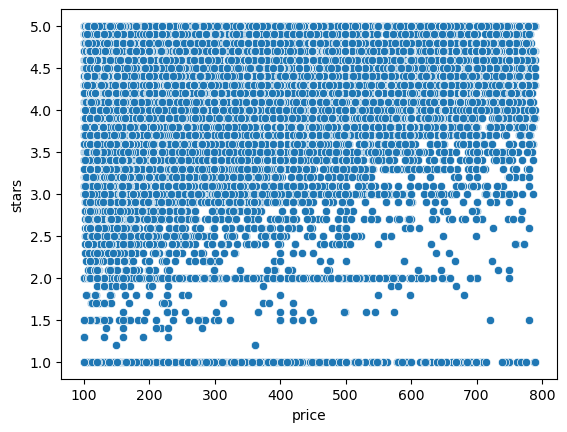

In [197]:
#scatter plot. i will continue to use df_price_rating

sns.scatterplot(data=df_price_rating, x="price", y="stars")
plt.show()

Insight: This doesn't tell us much because there's too much data. For higher priced products, there are fewer ratings between 1.5 and 3 stars.

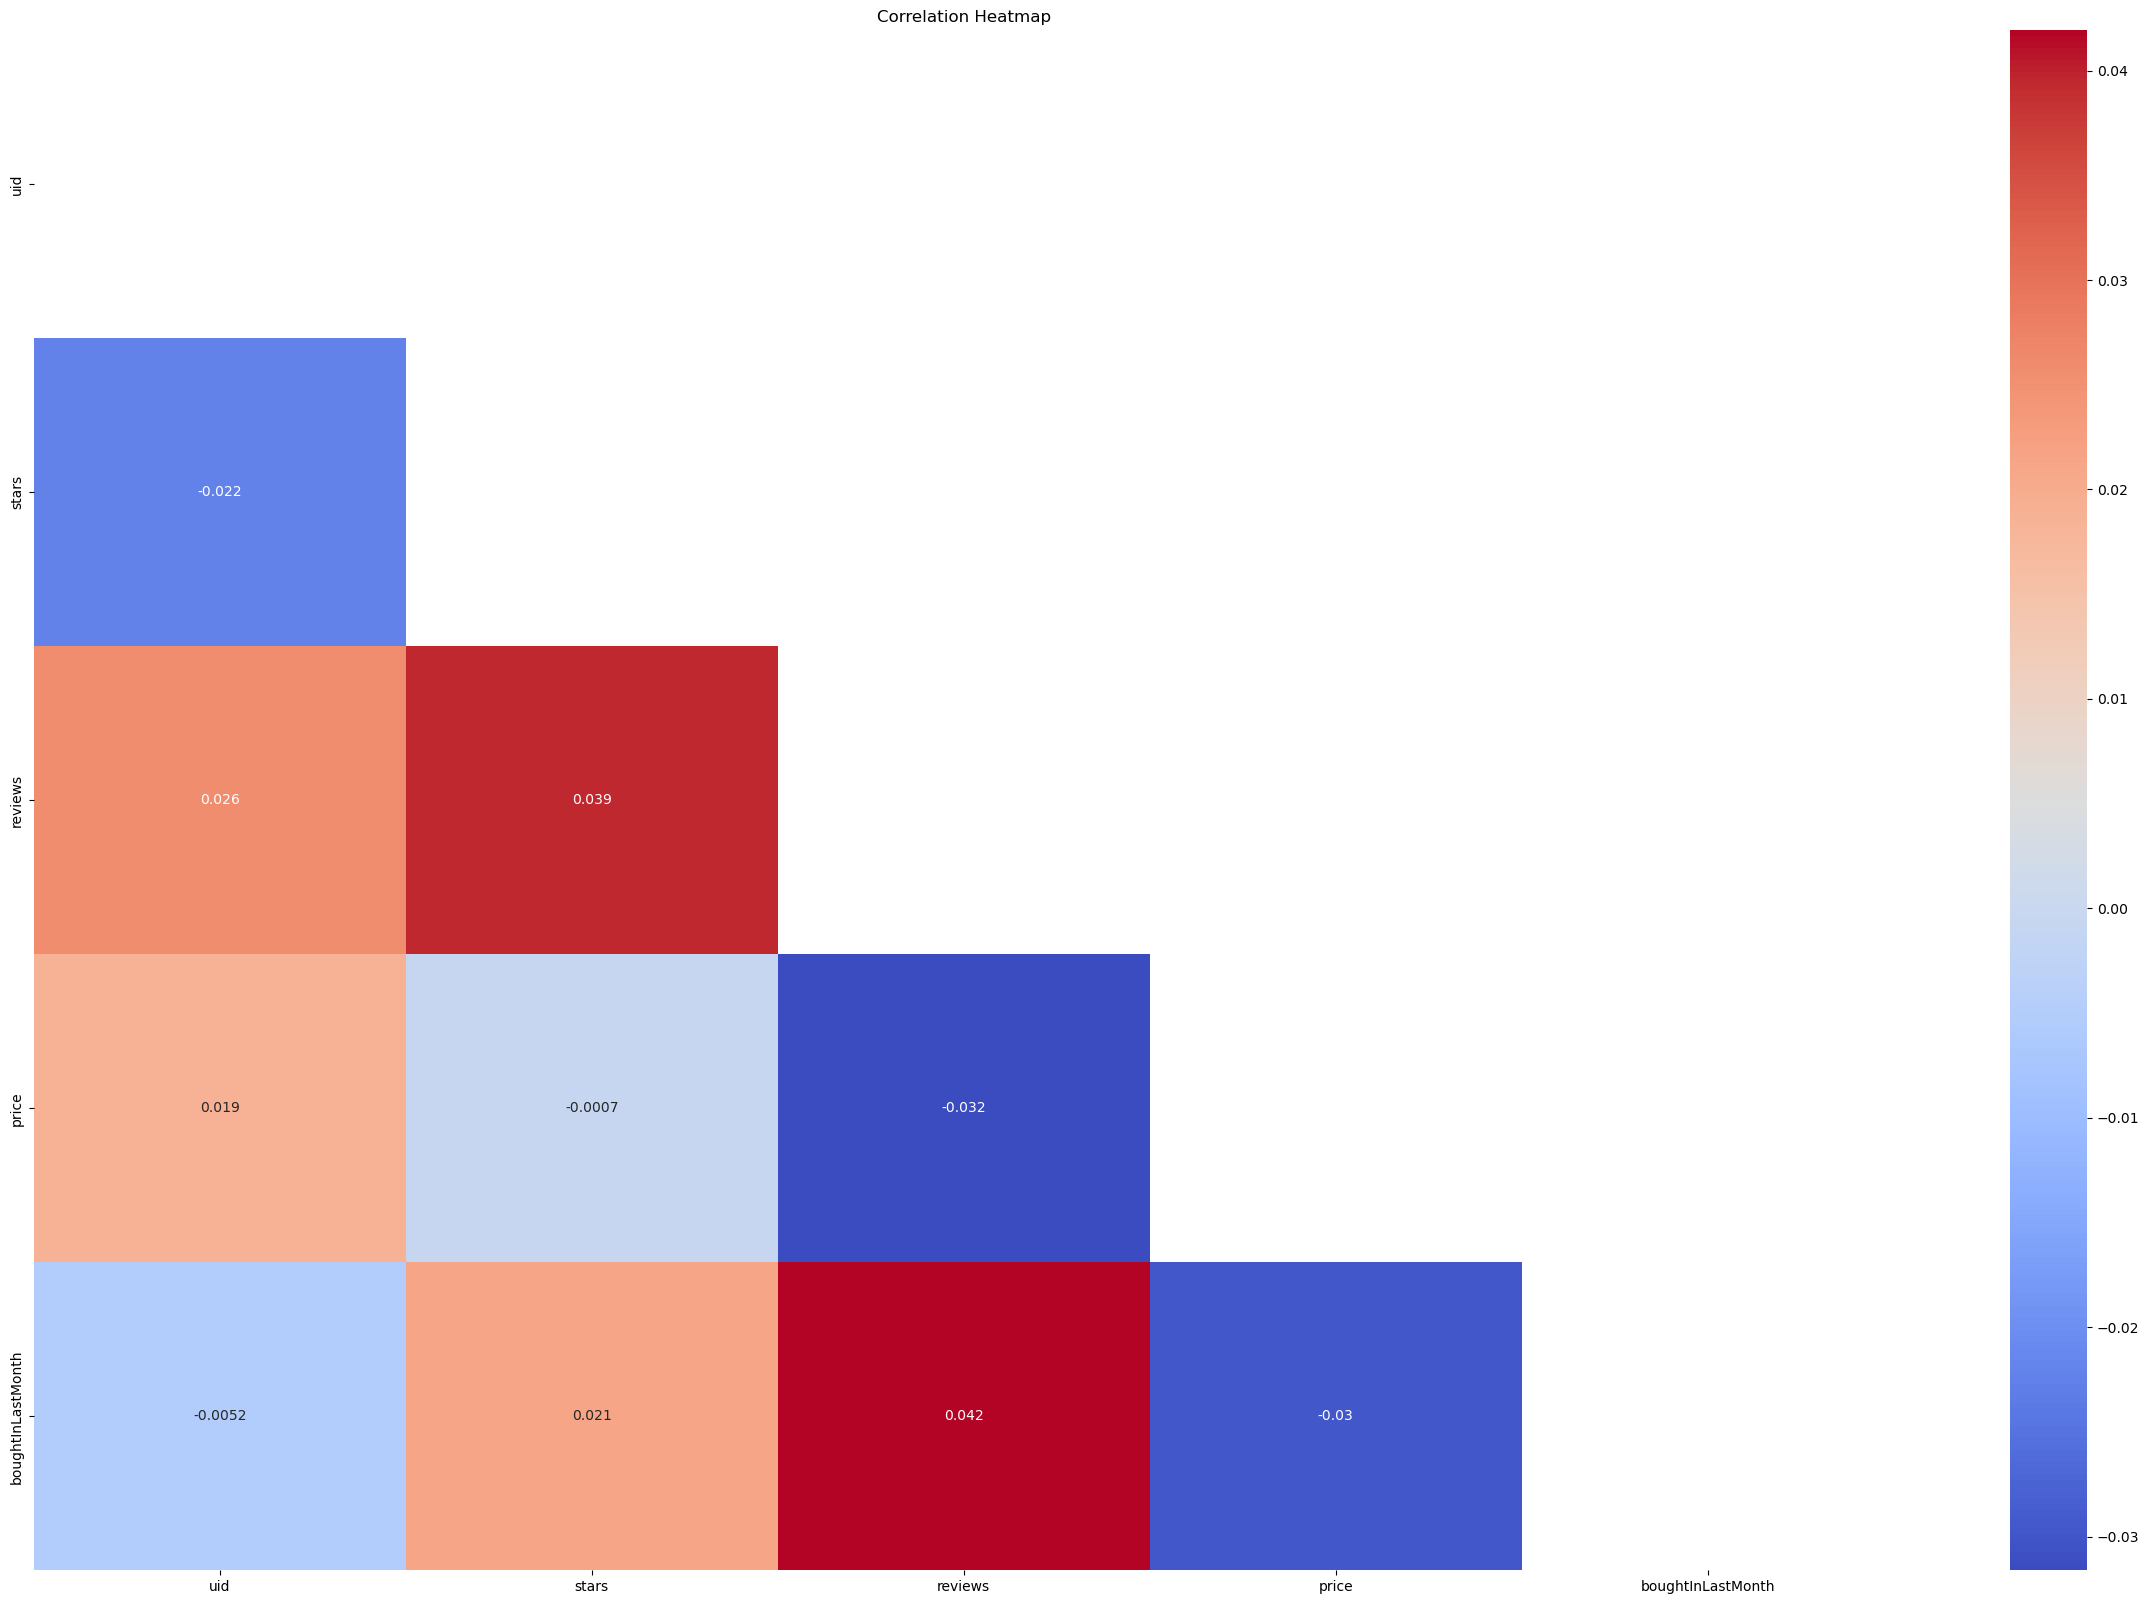

In [205]:
#all numerical valeus

num = df_price_rating.select_dtypes(include="number")

correlation_matrix = num.corr()

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))        #creating triangle matrix
plt.figure(figsize=(30, 20))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

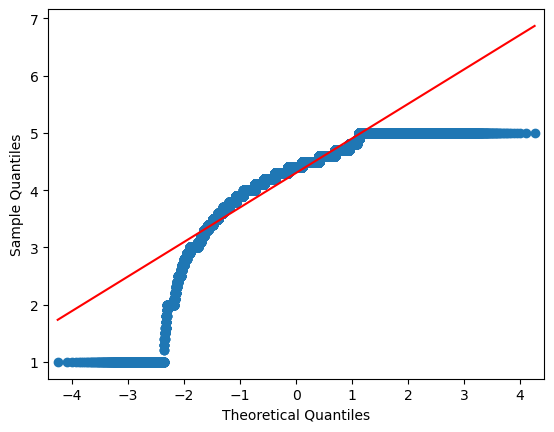

In [206]:
#qq plot

import statsmodels.api as sm

# Generating a Q-Q plot for 'SalePrice' to check if its distribution follows a normal distribution
sm.qqplot(df_price_rating['stars'], line='s');
plt.show()

Insight: Ratings don't follow a normal distribution. Unlike a normal distribution, ratings are concentrated in the upper bound, with some extremes at the lower end.

## Business Report

1. Relationship between categories and the bestseller status

Very few products in each product category have a bestseller status". There is only a weak correlation between category and bestseller status. This makes sense, if "bestseller" is defined as "bestseller in its category".
Further analysis should determine how much of a category's revenue and profit are generated from bestsellers vs non bestsellers.

2. Prices and Ratings Across Categories

After removing outliers from our analyis, we can see that there is huge price variation in "Sports & Outdoor", "Barebone PCs" and "Desktop PCs". Very noteworthy is "Media Streaming Devices", where prices are concentrated in three "low", "middle", and "high" pricepoints. Barebone PCs, Desktop PCs and Laptops have the highest average price.

The highest median rating can be found in "motorbike seat covers", but that might be due to thin data. Within the top categories by volume, "Barebon PCs" get the highest median rating.

3. Correlation

There is no meaningful correlation between prices and ratings. There is some positive correlation between ratings and "bought in last month", i.e. we should encourage our customers to review recently purchased items.

